--- 1. QUALITÀ DEI DATI E VOLUMI ---
Totale relazioni (Archi) grezze: 107030
Timestamp mancanti: 42.56%
Location mancanti: 68.55%



/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/65570133.py:71: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 1], data=df_types, y='actor_likely_type', x='count', palette='magma')
/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/65570133.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 0], data=df_actions, y='action', x='count', palette='crest')
/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/65570133.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 1]

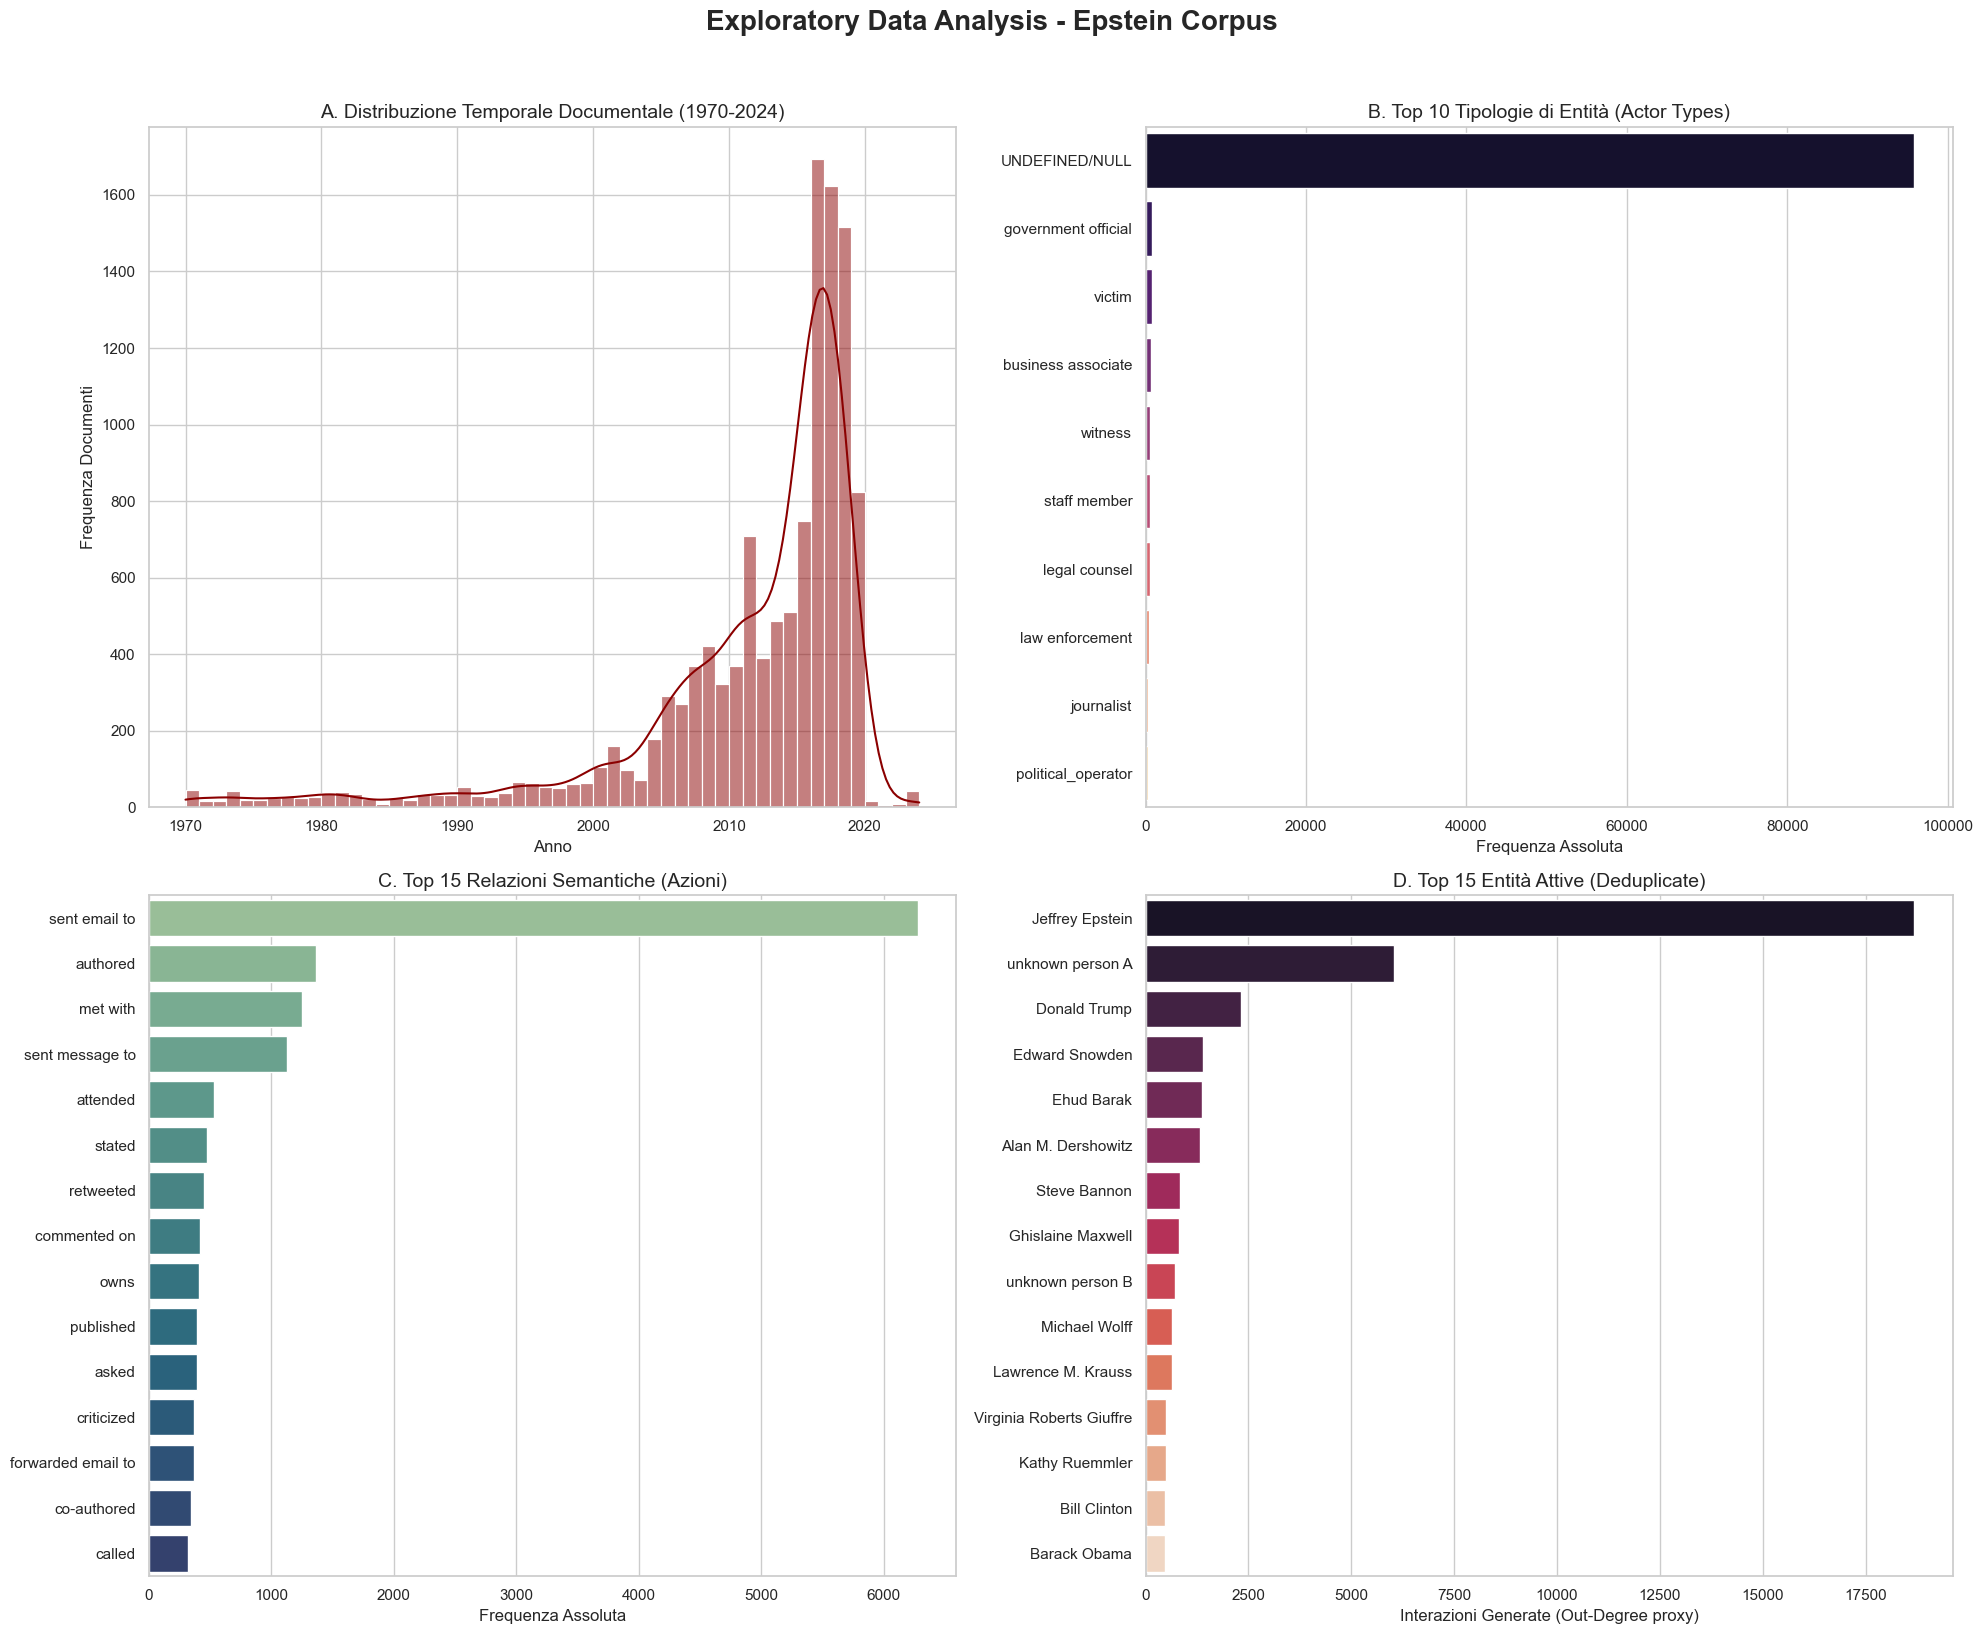

--- 2. GENERAZIONE DATASET MASTER ---
Estrazione completata: 107021 relazioni elaborate.
Dataset salvato con successo in: ../data/edges_base.csv


In [1]:
# ==============================================================================
# PROGETTO: Forensic Network Analysis: The Epstein Corpus
# NOTEBOOK 1: Exploratory Data Analysis (EDA) & Data Preparation
# OBIETTIVI: 
# 1. Valutazione della qualità dei dati temporali e spaziali.
# 2. Entity Resolution (Deduplicazione dei nodi) tramite alias canonici.
# 3. Analisi esplorativa orientata alle Research Questions (RQ1, RQ2).
# 4. Generazione del dataset master (edges) per la NLP Zero-Shot.
# ==============================================================================

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configurazione estetica per i plot (standard accademico)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'figure.autolayout': True})

# --- 1. INIZIALIZZAZIONE E CONNESSIONE AL DATABASE ---
db_path = '../data/document_analysis.db'
if not os.path.exists(db_path):
    raise FileNotFoundError(f"Database non trovato nel percorso: {db_path}")

conn = sqlite3.connect(db_path)

# --- 2. ANALISI DEI DATI MANCANTI E DISTRIBUZIONE TEMPORALE (RQ1 Focus) ---
# Obiettivo: Quantificare l'affidabilità dei timestamp nativi delle relazioni
# per lo studio del 'Context Drift' longitudinale.

print("--- 1. QUALITÀ DEI DATI E VOLUMI ---")
query_missing = """
SELECT 
    COUNT(*) as total_edges,
    SUM(CASE WHEN timestamp IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*) as missing_time_pct,
    SUM(CASE WHEN location IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*) as missing_loc_pct
FROM rdf_triples;
"""
df_missing = pd.read_sql_query(query_missing, conn)
print(f"Totale relazioni (Archi) grezze: {df_missing['total_edges'].iloc[0]}")
print(f"Timestamp mancanti: {df_missing['missing_time_pct'].iloc[0]:.2f}%")
print(f"Location mancanti: {df_missing['missing_loc_pct'].iloc[0]:.2f}%\n")


# --- 3. DEEP EDA & ENTITY RESOLUTION (RQ1, RQ2 Focus) ---
# Obiettivo: Generare una dashboard diagnostica applicando rigorosamente
# l'Entity Resolution (Deduplicazione) per evitare la frammentazione della Centrality.

fig, axes = plt.subplots(2, 2, figsize=(20, 16))
fig.suptitle('Exploratory Data Analysis - Epstein Corpus', fontsize=20, fontweight='bold', y=1.02)

# Grafico A: Distribuzione temporale dei documenti (Proxy per le epoche giudiziarie)
query_dates = "SELECT date_range_earliest FROM documents WHERE date_range_earliest IS NOT NULL AND date_range_earliest != ''"
df_dates = pd.read_sql_query(query_dates, conn)
df_dates['year'] = df_dates['date_range_earliest'].str.extract(r'(19\d{2}|20\d{2})').astype(float)
df_dates_clean = df_dates[(df_dates['year'] >= 1970) & (df_dates['year'] <= 2024)]
sns.histplot(ax=axes[0, 0], data=df_dates_clean, x='year', bins=int(df_dates_clean['year'].max() - df_dates_clean['year'].min()), kde=True, color='darkred')
axes[0, 0].set_title('A. Distribuzione Temporale Documentale (1970-2024)', fontsize=14)
axes[0, 0].set_xlabel('Anno')
axes[0, 0].set_ylabel('Frequenza Documenti')

# Grafico B: Tipologia di Attori (Focus RQ2: The Brokers)
# Risoluzione del problema di High Cardinality tramite limite esplorativo.
query_types = """
SELECT COALESCE(actor_likely_type, 'UNDEFINED/NULL') as actor_likely_type, COUNT(*) as count 
FROM rdf_triples 
GROUP BY actor_likely_type ORDER BY count DESC LIMIT 10
"""
df_types = pd.read_sql_query(query_types, conn)
sns.barplot(ax=axes[0, 1], data=df_types, y='actor_likely_type', x='count', palette='magma')
axes[0, 1].set_title('B. Top 10 Tipologie di Entità (Actor Types)', fontsize=14)
axes[0, 1].set_xlabel('Frequenza Assoluta')
axes[0, 1].set_ylabel('')

# Grafico C: Top Azioni / Verbi (Preparazione per la classificazione Zero-Shot)
query_actions = "SELECT action, COUNT(*) as count FROM rdf_triples WHERE action IS NOT NULL GROUP BY action ORDER BY count DESC LIMIT 15"
df_actions = pd.read_sql_query(query_actions, conn)
sns.barplot(ax=axes[1, 0], data=df_actions, y='action', x='count', palette='crest')
axes[1, 0].set_title('C. Top 15 Relazioni Semantiche (Azioni)', fontsize=14)
axes[1, 0].set_xlabel('Frequenza Assoluta')
axes[1, 0].set_ylabel('')

# Grafico D: Top Attori (Proxy di Out-Degree Centrality) CON ENTITY RESOLUTION
# Applicazione del LEFT JOIN per unificare gli alias prima del conteggio.
query_top_actors = """
SELECT COALESCE(e.canonical_name, r.actor) as canonical_actor, COUNT(*) as count
FROM rdf_triples r
LEFT JOIN entity_aliases e ON r.actor = e.original_name
GROUP BY canonical_actor
ORDER BY count DESC LIMIT 15
"""
df_top_actors = pd.read_sql_query(query_top_actors, conn)
sns.barplot(ax=axes[1, 1], data=df_top_actors, y='canonical_actor', x='count', palette='rocket')
axes[1, 1].set_title('D. Top 15 Entità Attive (Deduplicate)', fontsize=14)
axes[1, 1].set_xlabel('Interazioni Generate (Out-Degree proxy)')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()


# --- 4. DATA PREPARATION: GENERAZIONE DEL DATASET MASTER (EDGES) ---
# Obiettivo: Estrazione delle triple deduplicate e arricchimento contestuale.
# I metadati testuali (summary) vengono allegati per il successivo task di 
# NLP (Zero-Shot Text Classification).

print("--- 2. GENERAZIONE DATASET MASTER ---")
query_master_dedup = """
SELECT 
    r.id as edge_id,
    COALESCE(ea_actor.canonical_name, r.actor) as actor,
    r.action,
    COALESCE(ea_target.canonical_name, r.target) as target,
    r.timestamp as interaction_time,
    d.category as doc_category,
    d.one_sentence_summary,
    d.paragraph_summary,
    d.content_tags
FROM rdf_triples r
JOIN documents d ON r.doc_id = d.doc_id
LEFT JOIN entity_aliases ea_actor ON r.actor = ea_actor.original_name
LEFT JOIN entity_aliases ea_target ON r.target = ea_target.original_name
WHERE r.action IS NOT NULL AND r.action != ''
"""

df_master = pd.read_sql_query(query_master_dedup, conn)

# Pulizia temporale per la RQ1 (Estrazione anno certo)
df_master['interaction_year'] = df_master['interaction_time'].astype(str).str.extract(r'(19\d{2}|20\d{2})').astype(float)

# Export del checkpoint
output_path = '../data/edges_base.csv'
df_master.to_csv(output_path, index=False)

print(f"Estrazione completata: {len(df_master)} relazioni elaborate.")
print(f"Dataset salvato con successo in: {output_path}")

conn.close()

/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/412569159.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 0], data=df_targets, y='canonical_target', x='count', palette='mako')
/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/412569159.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 1], data=df_pairs, y='interaction_pair', x='count', palette='flare')
/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/412569159.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax

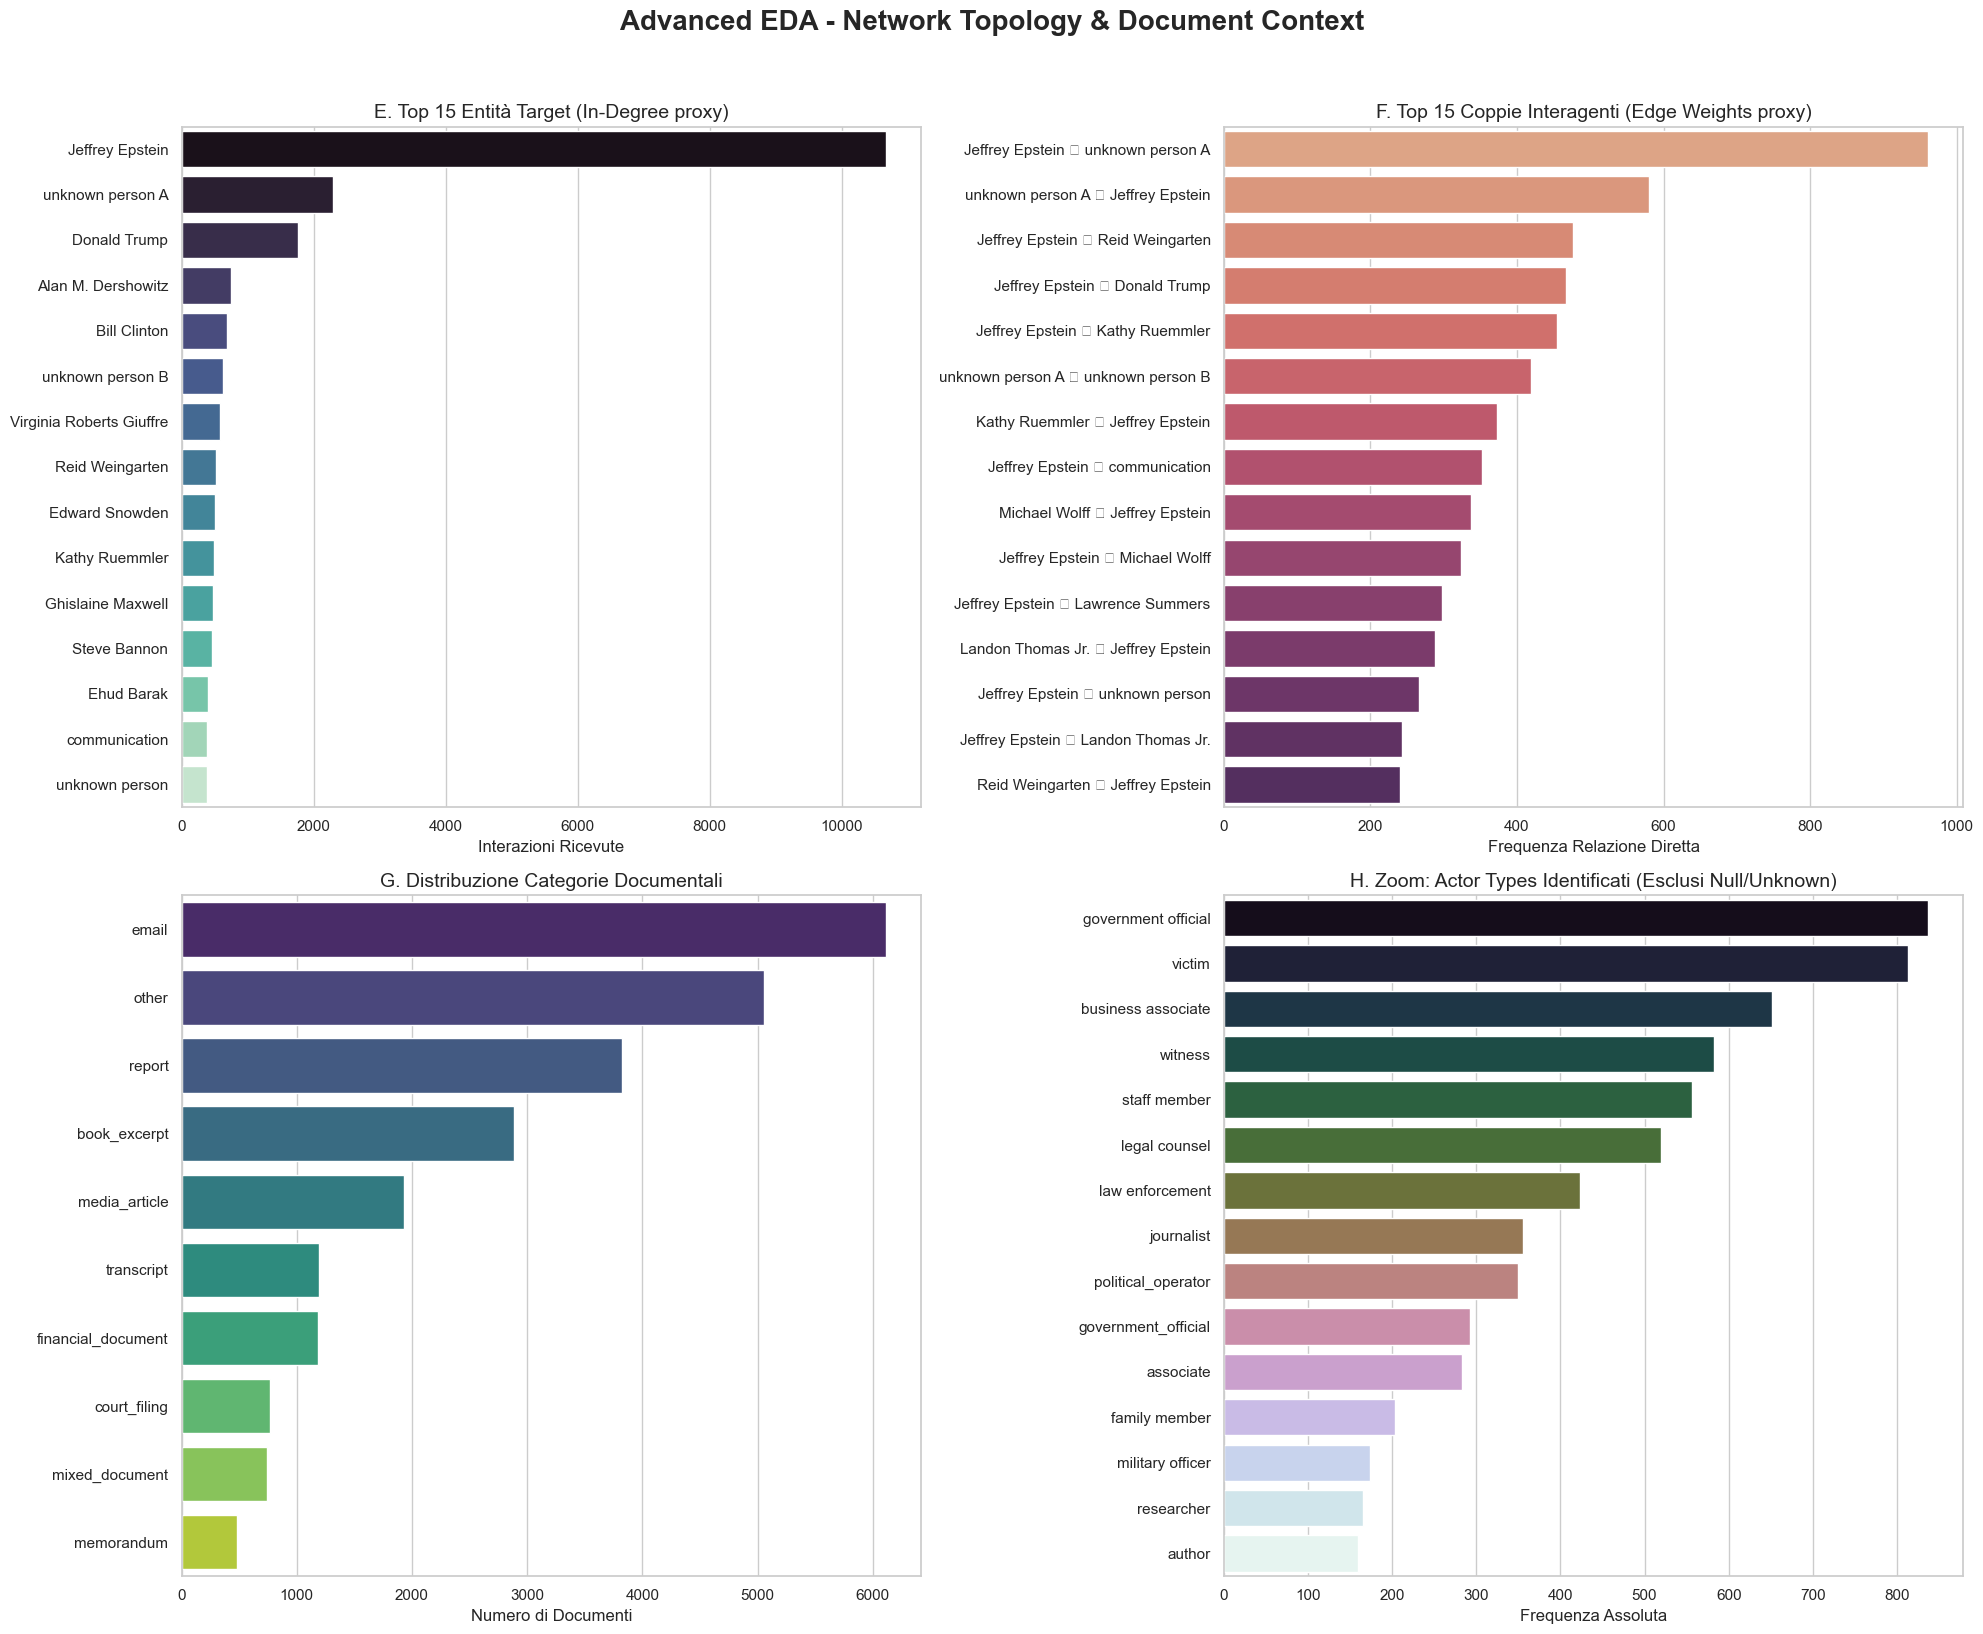

In [2]:
# ==============================================================================
# NOTEBOOK 1 - PARTE 2: Advanced Network EDA & Contextual Zoom
# OBIETTIVI: 
# 1. Analisi dei Target (In-Degree proxy).
# 2. Analisi delle Coppie (Edge Weights proxy).
# 3. Zoom sulle categorie testuali (Documenti e Tipi Entità validi).
# ==============================================================================

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setup estetico
sns.set_theme(style="whitegrid", palette="muted")
db_path = '../data/document_analysis.db'
conn = sqlite3.connect(db_path)

fig, axes = plt.subplots(2, 2, figsize=(20, 16))
fig.suptitle('Advanced EDA - Network Topology & Document Context', fontsize=20, fontweight='bold', y=1.02)

# ==========================================
# E. TOP 15 TARGET (Proxy di In-Degree Centrality)
# Perché: Sapere chi inizia l'azione (Soggetto) non basta. Chi è il destinatario
# principale delle azioni in questo network?
# ==========================================
query_targets = """
SELECT COALESCE(e.canonical_name, r.target) as canonical_target, COUNT(*) as count
FROM rdf_triples r
LEFT JOIN entity_aliases e ON r.target = e.original_name
GROUP BY canonical_target
ORDER BY count DESC LIMIT 15
"""
df_targets = pd.read_sql_query(query_targets, conn)
sns.barplot(ax=axes[0, 0], data=df_targets, y='canonical_target', x='count', palette='mako')
axes[0, 0].set_title('E. Top 15 Entità Target (In-Degree proxy)', fontsize=14)
axes[0, 0].set_xlabel('Interazioni Ricevute')
axes[0, 0].set_ylabel('')

# ==========================================
# F. TOP 15 COPPIE (Proxy di Edge Weight)
# Perché: Quali sono i "ponti" più trafficati della rete? Questo anticipa
# la ricerca strutturale dei broker (RQ2).
# ==========================================
query_pairs = """
SELECT 
    COALESCE(ea.canonical_name, r.actor) || ' ➔ ' || COALESCE(et.canonical_name, r.target) as interaction_pair, 
    COUNT(*) as count
FROM rdf_triples r
LEFT JOIN entity_aliases ea ON r.actor = ea.original_name
LEFT JOIN entity_aliases et ON r.target = et.original_name
GROUP BY interaction_pair
ORDER BY count DESC LIMIT 15
"""
df_pairs = pd.read_sql_query(query_pairs, conn)
sns.barplot(ax=axes[0, 1], data=df_pairs, y='interaction_pair', x='count', palette='flare')
axes[0, 1].set_title('F. Top 15 Coppie Interagenti (Edge Weights proxy)', fontsize=14)
axes[0, 1].set_xlabel('Frequenza Relazione Diretta')
axes[0, 1].set_ylabel('')

# ==========================================
# G. CATEGORIE DOCUMENTALI
# Perché: Serve a mappare il dominio (Legale vs Altro) da cui provengono i dati.
# ==========================================
query_doc_cat = "SELECT category, COUNT(*) as count FROM documents GROUP BY category ORDER BY count DESC LIMIT 10"
df_doc_cat = pd.read_sql_query(query_doc_cat, conn)
sns.barplot(ax=axes[1, 0], data=df_doc_cat, y='category', x='count', palette='viridis')
axes[1, 0].set_title('G. Distribuzione Categorie Documentali', fontsize=14)
axes[1, 0].set_xlabel('Numero di Documenti')
axes[1, 0].set_ylabel('')

# ==========================================
# H. ZOOM ACTOR TYPES (Escludendo i NULL)
# Perché: Ripariamo il grafico B precedente filtrando via il rumore di fondo 
# per vedere la vera distribuzione delle entità tipizzate con successo.
# ==========================================
query_types_zoom = """
SELECT actor_likely_type, COUNT(*) as count 
FROM rdf_triples 
WHERE actor_likely_type IS NOT NULL 
  AND actor_likely_type != 'UNDEFINED/NULL'
  AND actor_likely_type != 'unknown'
GROUP BY actor_likely_type 
ORDER BY count DESC LIMIT 15
"""
df_types_zoom = pd.read_sql_query(query_types_zoom, conn)
sns.barplot(ax=axes[1, 1], data=df_types_zoom, y='actor_likely_type', x='count', palette='cubehelix')
axes[1, 1].set_title('H. Zoom: Actor Types Identificati (Esclusi Null/Unknown)', fontsize=14)
axes[1, 1].set_xlabel('Frequenza Assoluta')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()

conn.close()

/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/3323466232.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=df_err_dist, y='category', x='error_count', palette='Reds_r')


--- INTEGRITÀ DEI DOCUMENTI ---
Documenti totali: 25232
Documenti con errori di analisi: 4084 (16.19%)
Tasso di successo: 83.81%



/var/folders/dn/wvrwwyms14g86kr68lrr5y_00000gn/T/ipykernel_85537/3323466232.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df_err_types, y='error_short', x='count', palette='magma')


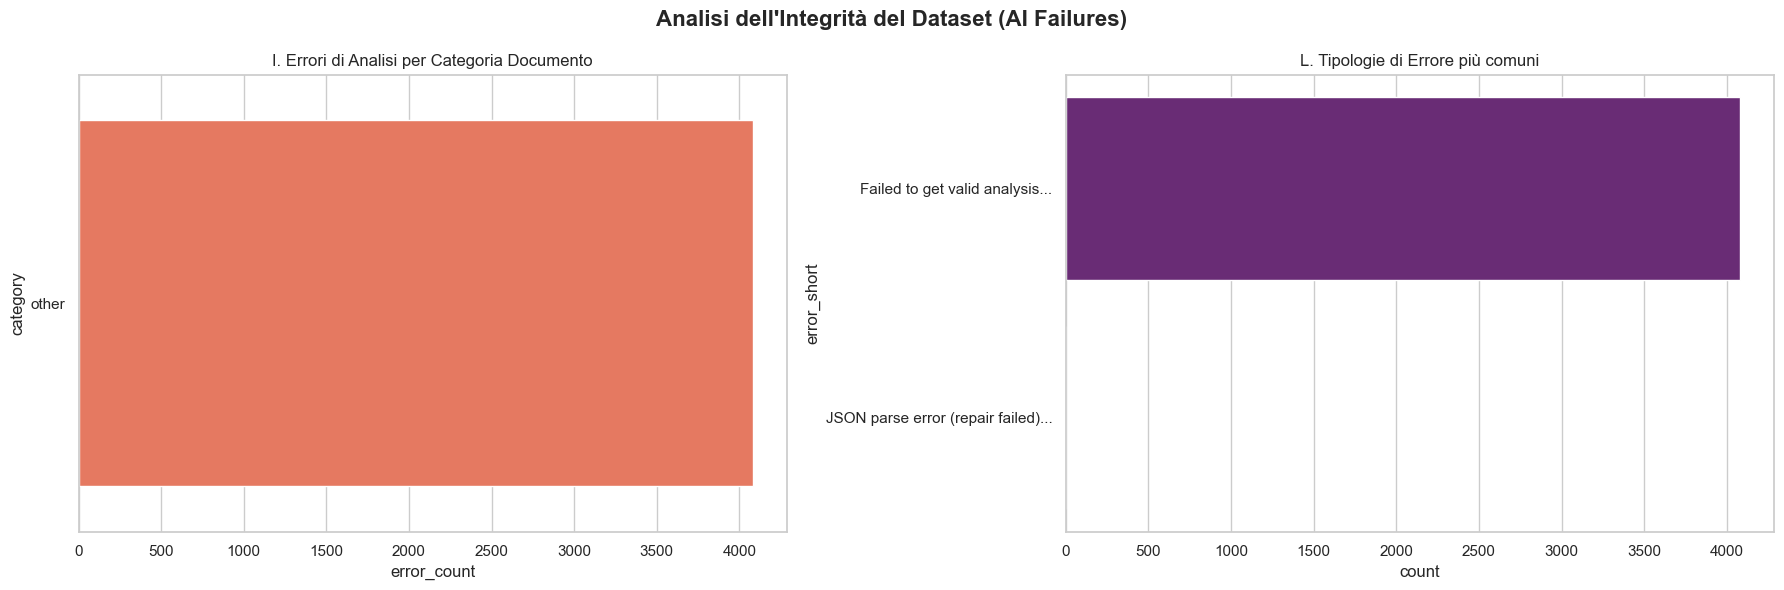

--- IMPATTO SUL NETWORK ---
Numero di relazioni (archi) potenzialmente corrotti: 0
Percentuale del grafo affetta: 0.00%


In [3]:
# ==============================================================================
# NOTEBOOK 1 - PARTE 3: Data Integrity & Error Profiling
# OBIETTIVI: 
# 1. Analisi dei fallimenti di estrazione (colonna 'error').
# 2. Correlazione tra errori e categorie di documenti.
# 3. Valutazione dell'impatto sulle triple RDF.
# ==============================================================================

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('../data/document_analysis.db')

# 1. Conteggio globale degli errori
query_errors = """
SELECT 
    COUNT(*) as total_docs,
    SUM(CASE WHEN error IS NOT NULL AND error != '' THEN 1 ELSE 0 END) as docs_with_errors
FROM documents;
"""
df_err_stats = pd.read_sql_query(query_errors, conn)

total = df_err_stats['total_docs'].iloc[0]
failed = df_err_stats['docs_with_errors'].iloc[0]
success_rate = ((total - failed) / total) * 100

print(f"--- INTEGRITÀ DEI DOCUMENTI ---")
print(f"Documenti totali: {total}")
print(f"Documenti con errori di analisi: {failed} ({100-success_rate:.2f}%)")
print(f"Tasso di successo: {success_rate:.2f}%\n")

# 2. Distribuzione degli errori per Categoria
# Perché: Forse l'AI fallisce più spesso sui log di volo (formati tabellari difficili)
# rispetto alle lettere o ai documenti legali?
query_err_dist = """
SELECT category, COUNT(*) as error_count
FROM documents
WHERE error IS NOT NULL AND error != ''
GROUP BY category
ORDER BY error_count DESC;
"""
df_err_dist = pd.read_sql_query(query_err_dist, conn)

# 3. Quali sono i messaggi di errore più comuni?
query_err_types = """
SELECT error, COUNT(*) as count
FROM documents
WHERE error IS NOT NULL AND error != ''
GROUP BY error
ORDER BY count DESC
LIMIT 5;
"""
df_err_types = pd.read_sql_query(query_err_types, conn)

# --- VISUALIZZAZIONE ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Analisi dell\'Integrità del Dataset (AI Failures)', fontsize=16, fontweight='bold')

# Grafico I: Errori per Categoria
sns.barplot(ax=axes[0], data=df_err_dist, y='category', x='error_count', palette='Reds_r')
axes[0].set_title('I. Errori di Analisi per Categoria Documento')

# Grafico L: Top Messaggi di Errore (Visualizziamo solo i primi caratteri per leggibilità)
df_err_types['error_short'] = df_err_types['error'].str[:50] + "..."
sns.barplot(ax=axes[1], data=df_err_types, y='error_short', x='count', palette='magma')
axes[1].set_title('L. Tipologie di Errore più comuni')

plt.tight_layout()
plt.show()

# --- IMPATTO SULLE TRIPLE ---
# Cruciale: quante triple derivano da documenti che hanno dato errore?
query_impact = """
SELECT COUNT(r.id) as impacted_triples
FROM rdf_triples r
JOIN documents d ON r.doc_id = d.doc_id
WHERE d.error IS NOT NULL AND d.error != '';
"""
impacted_count = pd.read_sql_query(query_impact, conn).iloc[0,0]
print(f"--- IMPATTO SUL NETWORK ---")
print(f"Numero di relazioni (archi) potenzialmente corrotti: {impacted_count}")
print(f"Percentuale del grafo affetta: {(impacted_count / 107030)*100:.2f}%")

conn.close()

In [4]:
import sqlite3
import pandas as pd
import json
import logging

logging.basicConfig(level=logging.INFO, format='%(levelname)s - %(message)s')

db_path = '../data/document_analysis.db'
conn = sqlite3.connect(db_path)

# Estraiamo i content_tags
query_tags = "SELECT content_tags FROM documents WHERE content_tags IS NOT NULL AND content_tags != ''"
df_tags = pd.read_sql_query(query_tags, conn)

logging.info(f"Trovati {len(df_tags)} documenti con tags.")

# I tag sono salvati come stringhe JSON (es. '["legal", "court", "subpoena"]'). 
# Dobbiamo decodificarli e "spalmarli" (explode) per contarli.
all_tags = []
for index, row in df_tags.iterrows():
    try:
        # Parsiamo la stringa JSON in una lista Python
        tags_list = json.loads(row['content_tags'])
        # Normalizziamo tutto in minuscolo per evitare duplicati (es. "Legal" vs "legal")
        all_tags.extend([str(tag).lower().strip() for tag in tags_list])
    except Exception as e:
        continue

# Creiamo un DataFrame con la lista di tutti i singoli tag
df_exploded = pd.DataFrame(all_tags, columns=['tag'])

# Contiamo i top 20
top_20_tags = df_exploded['tag'].value_counts().head(20)

print("\n--- TOP 20 CONTENT TAGS ---")
print(top_20_tags.to_string())

conn.close()

INFO - Trovati 25232 documenti con tags.



--- TOP 20 CONTENT TAGS ---
tag
house_oversight               1324
confidentiality_notice        1253
personal_correspondence       1216
attorney_client_privilege     1057
political_commentary           976
media_coverage                 865
legal_strategy                 760
reputation_management          755
email_communication            693
confidential_communication     674
email_correspondence           655
legal_proceedings              643
jeffrey_epstein                623
sexual_assault_allegations     602
legal_disclaimer               587
travel_planning                487
political_strategy             472
inside_information             471
international_relations        434
trump_administration           431
